In [10]:
import torch
import torch.nn.functional as F
import matplotlib.pyplot as plt
%matplotlib inline

In [11]:
words = open('names.txt', 'r').read().splitlines()

chars = sorted(list(set(''.join(words))))
stoi = {s:i+1 for i, s in enumerate(chars)}
stoi['.'] = 0

itos = {i:s for s, i in stoi.items()}
itos


{1: 'a',
 2: 'b',
 3: 'c',
 4: 'd',
 5: 'e',
 6: 'f',
 7: 'g',
 8: 'h',
 9: 'i',
 10: 'j',
 11: 'k',
 12: 'l',
 13: 'm',
 14: 'n',
 15: 'o',
 16: 'p',
 17: 'q',
 18: 'r',
 19: 's',
 20: 't',
 21: 'u',
 22: 'v',
 23: 'w',
 24: 'x',
 25: 'y',
 26: 'z',
 0: '.'}

In [12]:
block_size = 3

def build_ds(words):
    X, Y = [], []
    for w in words:
        #print(w)
        context = [0] * block_size
        for ch in (w + '.'):
            ix = stoi[ch]
            X.append(context)
            Y.append(ix)
            #print(''.join(itos[j] for j in context), '----->', itos[ix])
            context = context[1:] + [ix]

    X = torch.tensor(X)
    Y = torch.tensor(Y)
    print(X.shape, Y.shape)
    return X, Y

import random
random.shuffle(words)
n1 = int(0.8 * len(words))
n2 = int(0.9*len(words))

Xtr, Ytr = build_ds(words[:n1])
Xdev, Ydev = build_ds(words[n1:n2])
Xte, Yte = build_ds(words[n2:])


torch.Size([182580, 3]) torch.Size([182580])
torch.Size([22801, 3]) torch.Size([22801])
torch.Size([22765, 3]) torch.Size([22765])


In [13]:
#setup
C = torch.randn(27, 10)
W1 = torch.randn(30, 200) * (5/3) / 30**0.5
b1 = torch.randn(200) * 0.01
W2 = torch.randn(200, 27) * 0.01
b2 = torch.randn(27) * 0
params = [C, W1, b1, W2, b2]
for p in params:
    p.requires_grad = True
    p.grad = None

lri = []
lossi = []
stepi = []

lre = torch.linspace(-3, 0, 1000)
lrs = 10**lre

#forward pass
for i in range(20000):
    #minibatching construct
    ix = torch.randint(0, Xtr.shape[0], (32,))


    emb = C[Xtr[ix]]
    temp = emb.view(-1, 30) @ W1 + b1
    h = torch.tanh(temp)
    logits = h @ W2 + b2

    #backward pass
    for p in params:
        p.grad = None
    loss = F.cross_entropy(logits, Ytr[ix])
    loss.backward()
    lr = 0.1 if i < 100000 else 0.01
    #update
    for p in params:
        p.data += -lr * p.grad
    #lri.append(lre[i])
    #lossi.append(loss.item())
    stepi.append(i)
    lossi.append(loss.log10().item())

print(loss.item())



2.2246241569519043


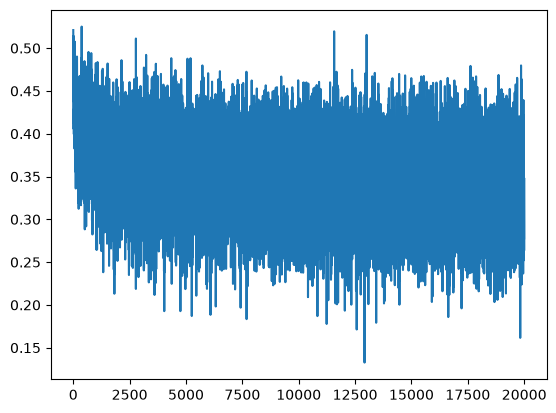

In [14]:
plt.plot(stepi, lossi)

In [15]:
emb = C[Xtr] # (32, 3, 2)
h = torch.tanh(emb.view(-1, 30) @ W1 + b1) # (32, 100)
logits = h @ W2 + b2 # (32, 27)
loss = F.cross_entropy(logits, Ytr)
loss

tensor(2.2147, grad_fn=<NllLossBackward0>)

In [16]:
emb = C[Xdev] # (32, 3, 2)
h = torch.tanh(emb.view(-1, 30) @ W1 + b1) # (32, 100)
logits = h @ W2 + b2 # (32, 27)
loss = F.cross_entropy(logits, Ydev)
loss

tensor(2.2539, grad_fn=<NllLossBackward0>)

In [18]:
# sample from the model
g = torch.Generator().manual_seed(2147483647 + 10)

for _ in range(20):
    
    out = []
    context = [0] * block_size # initialize with all ...
    while True:
      emb = C[torch.tensor([context])] # (1,block_size,d)
      h = torch.tanh(emb.view(1, -1) @ W1 + b1)
      logits = h @ W2 + b2
      probs = F.softmax(logits, dim=1)
      ix = torch.multinomial(probs, num_samples=1, generator=g).item()
      context = context[1:] + [ix]
      out.append(ix)
      if ix == 0:
        break
    
    print(''.join(itos[i] for i in out))


logits

carmahia.
brilyn.
kimreigh.
tyrence.
ane.
rahnen.
amerynci.
aquil.
ramariachaiivon.
neilyn.
amonia.
denianna.
lil.
alianni.
water.
giahrisia.
kaelissual.
edde.
oia.
gianahya.


tensor([[ 4.6517, -0.1093,  0.9666,  0.0434,  0.0866, -0.5404, -1.4150, -1.1099,
          2.5990,  0.2094, -0.4840, -0.8127,  0.8428,  1.3231,  3.5973, -3.1198,
         -1.0431, -1.3983,  0.3520,  1.5142,  0.1737, -0.9308, -0.2050, -1.0076,
         -2.6735, -0.9723, -0.4825]], grad_fn=<AddBackward0>)